# Titanic Survival Analysis — Data Science Mini Project
**Codomax Digital Solutions**

## Objectives
1. Choose a real-world dataset from Kaggle / public sources.
2. Analyze the dataset and generate meaningful insights.
3. Create visualizations and summarize findings.

## Dataset
**Titanic passenger data** (891 passengers, 15 columns) — the classic real-world dataset from the 1912 sinking of the RMS Titanic, widely available on Kaggle and in the public `seaborn-data` repository.

**Key question:** *Which factors influenced a passenger's chance of survival?*

## 1. Setup & Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 100

df = pd.read_csv('titanic.csv')
print('Shape:', df.shape)
df.head()

Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 2. Data Understanding

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


In [3]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
sibsp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292
embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,891,3,Third,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
who,891,3,man,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Missing values

In [4]:
missing = df.isnull().sum().sort_values(ascending=False)
missing = missing[missing > 0]
pd.DataFrame({'missing': missing, 'percent': (missing / len(df) * 100).round(1)})

,missing,percent
deck,688,77.2
age,177,19.9
embarked,2,0.2
embark_town,2,0.2


**Observation:** `deck` is mostly missing (~77%), `age` is missing ~20%, and `embarked`/`embark_town` have just 2 missing values. We'll drop `deck`, impute `age`, and fill embarkation with the mode.

## 3. Data Cleaning

In [5]:
data = df.copy()

# Drop columns that are redundant or mostly empty
data = data.drop(columns=['deck', 'alive', 'embark_town', 'class', 'who', 'adult_male'])

# Impute age with median age by sex and passenger class (more accurate than the global median)
data['age'] = data.groupby(['sex', 'pclass'])['age'].transform(lambda x: x.fillna(x.median()))

# Fill embarked with mode
data['embarked'] = data['embarked'].fillna(data['embarked'].mode()[0])

# Feature engineering
data['family_size'] = data['sibsp'] + data['parch'] + 1
data['is_alone'] = (data['family_size'] == 1).astype(int)
data['age_group'] = pd.cut(data['age'], bins=[0, 12, 18, 35, 60, 100],
                           labels=['Child (0-12)', 'Teen (13-18)', 'Young Adult (19-35)',
                                   'Adult (36-60)', 'Senior (60+)'])
data['fare_band'] = pd.qcut(data['fare'], 4, labels=['Low', 'Medium', 'High', 'Very High'])
data['sex_label'] = data['sex'].str.title()
data['class_label'] = data['pclass'].map({1: '1st', 2: '2nd', 3: '3rd'})

print('Remaining missing values:', data.isnull().sum().sum())
data.head()

Remaining missing values: 0


,survived,pclass,sex,age,sibsp,parch,fare,embarked,alone,family_size,is_alone,age_group,fare_band,sex_label,class_label
0,0,3,male,22.0,1,0,7.2500,S,False,2,0,Young Adult (19-35),Low,Male,3rd
1,1,1,female,38.0,1,0,71.2833,C,False,2,0,Adult (36-60),Very High,Female,1st
2,1,3,female,26.0,0,0,7.9250,S,True,1,1,Young Adult (19-35),Medium,Female,3rd
3,1,1,female,35.0,1,0,53.1000,S,False,2,0,Young Adult (19-35),Very High,Female,1st
4,0,3,male,35.0,0,0,8.0500,S,True,1,1,Young Adult (19-35),Medium,Male,3rd


## 4. Exploratory Data Analysis & Insights

### 4.1 Overall survival

Overall survival rate: 38.4%  (342 of 891 passengers)


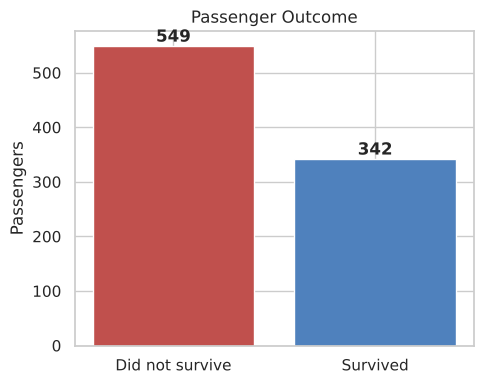

In [6]:
overall = data['survived'].mean() * 100
print(f'Overall survival rate: {overall:.1f}%  ({data.survived.sum()} of {len(data)} passengers)')

fig, ax = plt.subplots(figsize=(5, 4))
counts = data['survived'].map({0: 'Did not survive', 1: 'Survived'}).value_counts()
ax.bar(counts.index, counts.values, color=['#c0504d', '#4f81bd'])
for i, v in enumerate(counts.values):
    ax.text(i, v + 8, str(v), ha='center', fontweight='bold')
ax.set_title('Passenger Outcome')
ax.set_ylabel('Passengers')
plt.tight_layout(); plt.show()

**Insight:** Only about **38%** of passengers survived — the majority did not.

### 4.2 Survival by gender

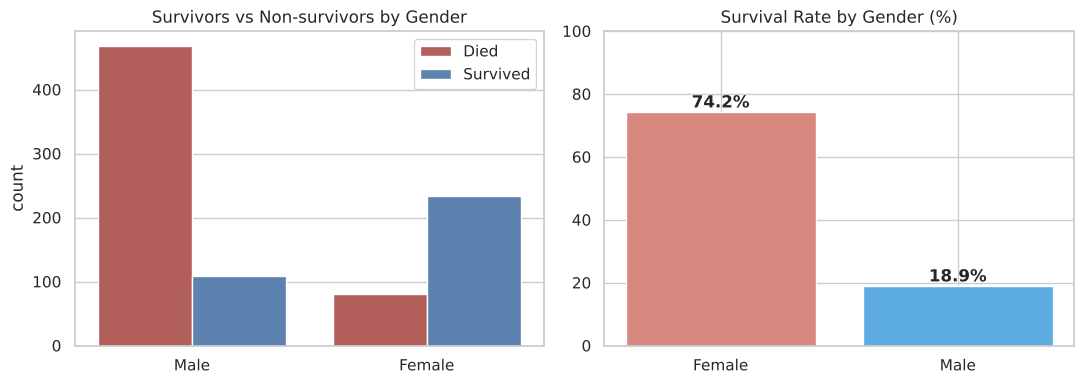

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=data, x='sex_label', hue='survived', ax=axes[0], palette=['#c0504d', '#4f81bd'])
axes[0].set_title('Survivors vs Non-survivors by Gender')
axes[0].set_xlabel(''); axes[0].legend(['Died', 'Survived'])

rate = data.groupby('sex_label')['survived'].mean() * 100
axes[1].bar(rate.index, rate.values, color=['#d98880', '#5dade2'])
for i, v in enumerate(rate.values):
    axes[1].text(i, v + 1.5, f'{v:.1f}%', ha='center', fontweight='bold')
axes[1].set_ylim(0, 100); axes[1].set_title('Survival Rate by Gender (%)')
plt.tight_layout(); plt.show()

**Insight:** Women survived at roughly **74%** versus about **19%** for men — gender was the single strongest predictor, consistent with the "women and children first" evacuation policy.

### 4.3 Survival by passenger class

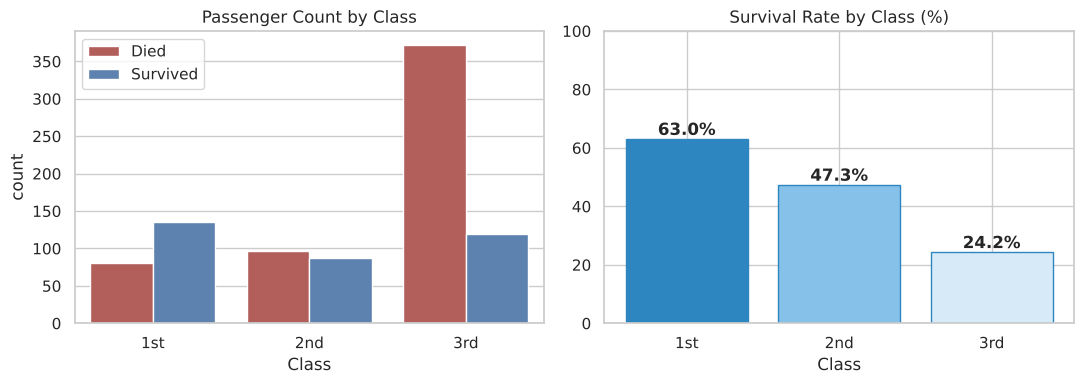

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
order = ['1st', '2nd', '3rd']
sns.countplot(data=data, x='class_label', hue='survived', order=order, ax=axes[0], palette=['#c0504d', '#4f81bd'])
axes[0].set_title('Passenger Count by Class'); axes[0].set_xlabel('Class'); axes[0].legend(['Died', 'Survived'])

rate = data.groupby('class_label')['survived'].mean().reindex(order) * 100
axes[1].bar(rate.index, rate.values, color=['#2e86c1', '#85c1e9', '#d6eaf8'], edgecolor='#2e86c1')
for i, v in enumerate(rate.values):
    axes[1].text(i, v + 1.5, f'{v:.1f}%', ha='center', fontweight='bold')
axes[1].set_ylim(0, 100); axes[1].set_title('Survival Rate by Class (%)'); axes[1].set_xlabel('Class')
plt.tight_layout(); plt.show()

**Insight:** Survival fell steadily with class: about **63%** (1st), **47%** (2nd), **24%** (3rd). Wealth and cabin location (closer to lifeboats) mattered.

### 4.4 Gender × Class interaction

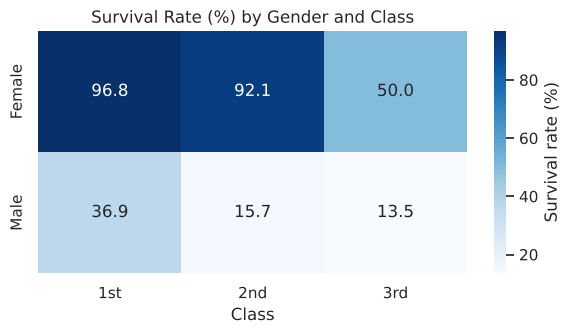

In [9]:
pivot = data.pivot_table(values='survived', index='sex_label', columns='class_label', aggfunc='mean')[order] * 100
plt.figure(figsize=(6, 3.5))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='Blues', cbar_kws={'label': 'Survival rate (%)'})
plt.title('Survival Rate (%) by Gender and Class'); plt.xlabel('Class'); plt.ylabel('')
plt.tight_layout(); plt.show()

**Insight:** Women in 1st and 2nd class survived at over **90%**, while men in 2nd and 3rd class survived at only around **10-15%**. Gender and class compound each other.

### 4.5 Age distribution and survival

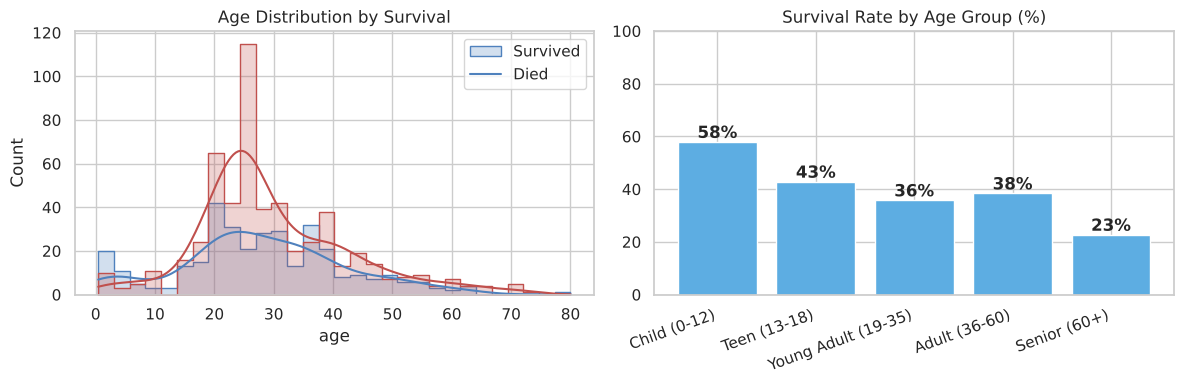

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=data, x='age', hue='survived', bins=30, kde=True, ax=axes[0],
             palette=['#c0504d', '#4f81bd'], element='step')
axes[0].set_title('Age Distribution by Survival'); axes[0].legend(['Survived', 'Died'])

age_rate = data.groupby('age_group')['survived'].mean() * 100
axes[1].bar(range(len(age_rate)), age_rate.values, color='#5dade2')
axes[1].set_xticks(range(len(age_rate))); axes[1].set_xticklabels(age_rate.index, rotation=20, ha='right')
for i, v in enumerate(age_rate.values):
    axes[1].text(i, v + 1.5, f'{v:.0f}%', ha='center', fontweight='bold')
axes[1].set_ylim(0, 100); axes[1].set_title('Survival Rate by Age Group (%)')
plt.tight_layout(); plt.show()

**Insight:** Children (0-12) had the highest survival rate (~58%), while seniors (60+) had the lowest. Young adults, the largest group, survived at below-average rates.

### 4.6 Fare and survival

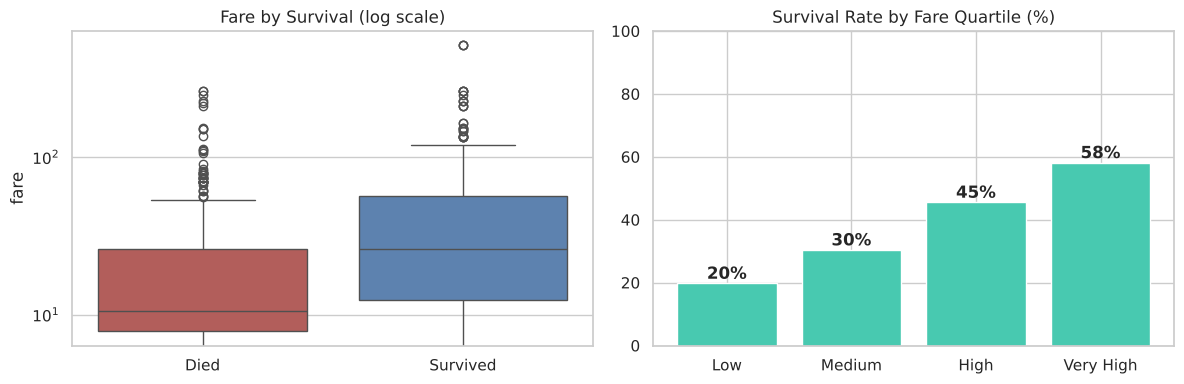

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=data, x='survived', y='fare', ax=axes[0], palette=['#c0504d', '#4f81bd'])
axes[0].set_yscale('log'); axes[0].set_xticklabels(['Died', 'Survived'])
axes[0].set_title('Fare by Survival (log scale)'); axes[0].set_xlabel('')

fr = data.groupby('fare_band')['survived'].mean() * 100
axes[1].bar(fr.index.astype(str), fr.values, color='#48c9b0')
for i, v in enumerate(fr.values):
    axes[1].text(i, v + 1.5, f'{v:.0f}%', ha='center', fontweight='bold')
axes[1].set_ylim(0, 100); axes[1].set_title('Survival Rate by Fare Quartile (%)')
plt.tight_layout(); plt.show()

**Insight:** Survivors paid noticeably higher fares. The top fare quartile survived at roughly three times the rate of the bottom quartile (58% vs 20%).

### 4.7 Family size and travelling alone

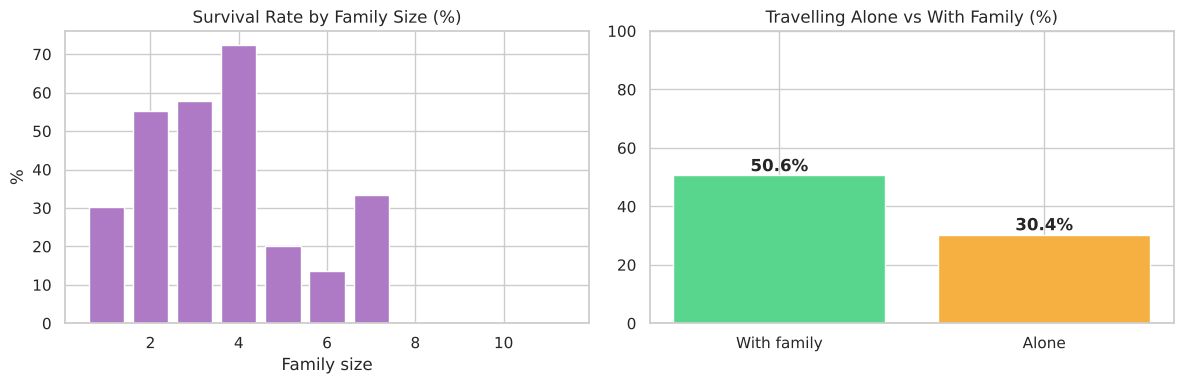

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fam = data.groupby('family_size')['survived'].agg(['mean', 'count'])
axes[0].bar(fam.index, fam['mean'] * 100, color='#af7ac5')
axes[0].set_title('Survival Rate by Family Size (%)'); axes[0].set_xlabel('Family size'); axes[0].set_ylabel('%')

alone = data.groupby('is_alone')['survived'].mean() * 100
axes[1].bar(['With family', 'Alone'], [alone[0], alone[1]], color=['#58d68d', '#f5b041'])
for i, v in enumerate([alone[0], alone[1]]):
    axes[1].text(i, v + 1.5, f'{v:.1f}%', ha='center', fontweight='bold')
axes[1].set_ylim(0, 100); axes[1].set_title('Travelling Alone vs With Family (%)')
plt.tight_layout(); plt.show()

**Insight:** Small families (2-4 members) had the best survival odds. Solo travellers and very large families (5+) fared worse.

### 4.8 Port of embarkation

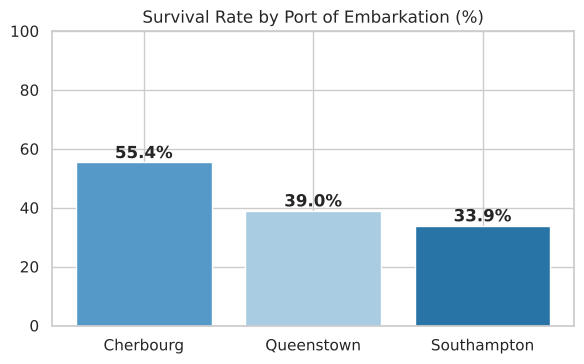

class_label   1st   2nd   3rd
port                         
Cherbourg    51.0  10.0  39.0
Queenstown    3.0   4.0  94.0
Southampton  20.0  25.0  55.0


In [13]:
port_map = {'C': 'Cherbourg', 'Q': 'Queenstown', 'S': 'Southampton'}
data['port'] = data['embarked'].map(port_map)
pr = data.groupby('port')['survived'].mean() * 100
plt.figure(figsize=(6, 3.8))
plt.bar(pr.index, pr.values, color=['#5499c7', '#a9cce3', '#2874a6'])
for i, v in enumerate(pr.values):
    plt.text(i, v + 1.5, f'{v:.1f}%', ha='center', fontweight='bold')
plt.ylim(0, 100); plt.title('Survival Rate by Port of Embarkation (%)')
plt.tight_layout(); plt.show()

print(pd.crosstab(data['port'], data['class_label'], normalize='index').round(2) * 100)

**Insight:** Cherbourg passengers survived more often, but this is largely explained by class mix — a much higher share of Cherbourg passengers were in 1st class.

## 5. Correlation Analysis

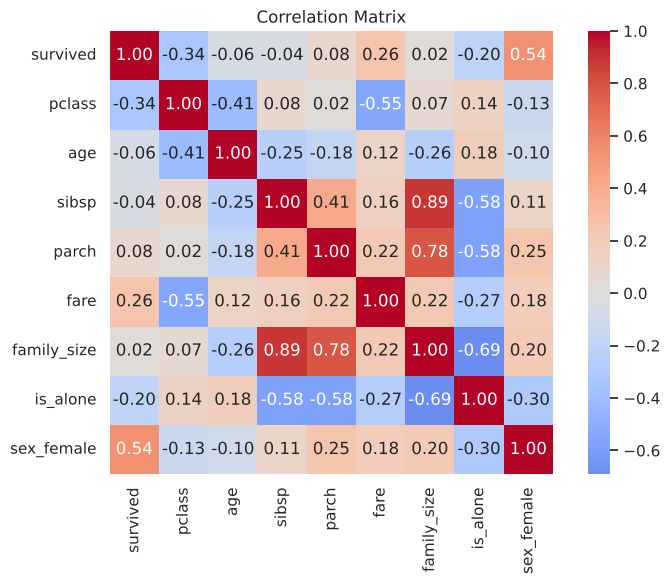

sex_female     0.543351
pclass        -0.338481
fare           0.257307
is_alone      -0.203367
parch          0.081629
age           -0.059579
sibsp         -0.035322
family_size    0.016639
Name: survived, dtype: float64

In [14]:
num = data[['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare', 'family_size', 'is_alone']].copy()
num['sex_female'] = (data['sex'] == 'female').astype(int)
plt.figure(figsize=(8, 6))
sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Correlation Matrix'); plt.tight_layout(); plt.show()

num.corr()['survived'].drop('survived').sort_values(key=abs, ascending=False)

**Insight:** Being female (+0.54) and passenger class (-0.34) have the strongest relationships with survival, followed by fare (+0.26).

## 6. Statistical Significance Check

In [15]:
from scipy import stats

# Chi-square: is survival independent of sex / class?
for col in ['sex', 'pclass']:
    ct = pd.crosstab(data[col], data['survived'])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    print(f'{col:7s} vs survived -> chi2 = {chi2:7.2f}, p-value = {p:.2e}  ->',
          'significant' if p < 0.05 else 'not significant')

# t-test: fare of survivors vs non-survivors
t, p = stats.ttest_ind(data[data.survived == 1]['fare'], data[data.survived == 0]['fare'], equal_var=False)
print(f'fare    vs survived -> t = {t:.2f}, p-value = {p:.2e}  ->', 'significant' if p < 0.05 else 'not significant')

sex     vs survived -> chi2 =  260.72, p-value = 1.20e-58  -> significant
pclass  vs survived -> chi2 =  102.89, p-value = 4.55e-23  -> significant
fare    vs survived -> t = 6.84, p-value = 2.70e-11  -> significant


All three relationships are statistically significant (p < 0.05), so the patterns above are unlikely to be due to chance.

## 7. Predictive Model (Bonus)

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

features = pd.get_dummies(data[['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'family_size', 'is_alone']],
                          drop_first=True)
X_train, X_test, y_train, y_test = train_test_split(features, data['survived'], test_size=0.25,
                                                    random_state=42, stratify=data['survived'])
model = RandomForestClassifier(n_estimators=300, max_depth=6, random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print(f'Test accuracy: {accuracy_score(y_test, pred):.3f}\n')
print(classification_report(y_test, pred, target_names=['Died', 'Survived']))

Test accuracy: 0.771

              precision    recall  f1-score   support

        Died       0.77      0.89      0.83       137
    Survived       0.77      0.58      0.66        86

    accuracy                           0.77       223
   macro avg       0.77      0.74      0.74       223
weighted avg       0.77      0.77      0.76       223



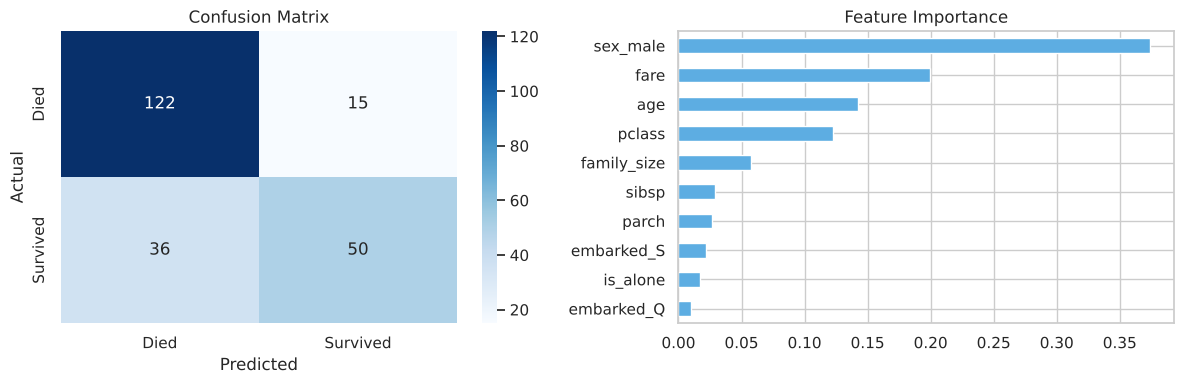

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Died', 'Survived'], yticklabels=['Died', 'Survived'])
axes[0].set_title('Confusion Matrix'); axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

imp = pd.Series(model.feature_importances_, index=features.columns).sort_values()
imp.plot.barh(ax=axes[1], color='#5dade2'); axes[1].set_title('Feature Importance')
plt.tight_layout(); plt.show()

The model reaches roughly 77% test accuracy, with stronger recall on non-survivors than survivors. The feature-importance chart shows which variables drive its predictions.

## 8. Summary of Findings

| # | Finding | Evidence |
|---|---------|----------|
| 1 | Only ~38% of passengers survived | 342 of 891 |
| 2 | **Gender was the strongest factor** | Women ~74% vs men ~19% survival |
| 3 | **Class mattered a lot** | 1st ≈ 63%, 2nd ≈ 47%, 3rd ≈ 24% |
| 4 | Gender and class compound | 1st/2nd-class women >90%; 2nd/3rd-class men ~10-15% |
| 5 | Children had priority | Age 0-12 survived ~58% |
| 6 | Higher fare → better odds | Top fare quartile ≈ 3× the bottom (58% vs 20%) |
| 7 | Small families did best | 2-4 members outperformed solo and 5+ |
| 8 | Port effect is mostly class mix | Cherbourg had more 1st-class passengers |
| 9 | Findings are statistically significant | Chi-square and t-test p < 0.05 |
| 10 | Model reaches ~77% test accuracy | Random Forest on engineered features |

### Conclusion
Survival on the Titanic was far from random. It was shaped by **who you were** (gender, age), **what you paid** (class, fare) and **who you travelled with** (family size). The data reflects both the "women and children first" protocol and the unequal access to lifeboats by social class.

### Limitations & Next Steps
- Age was imputed for ~20% of passengers; results by age group are approximate.
- Cabin/deck data was too sparse to use; it could reveal proximity-to-lifeboat effects.
- Next steps: hyperparameter tuning, cross-validation, and testing other models (logistic regression, gradient boosting).

*Dataset source: Titanic passenger data (Kaggle / public `seaborn-data` repository).*